# 模块二：失败归因分析

## 电商智能客服 RAG 系统多维度评测与根因分析

---

### 🎯 分析目的

对模块一筛出的失败用例进行根因标注，回答 **"为什么失败"**。

---

### 📋 分析内容

1. **失败用例概览** — 按分支 / 类型 / 难度分布
2. **根因分类体系设计** — 8 类根因代码与判定规则
3. **自动根因标注** — 优先级匹配算法
4. **根因分布分析** — 饼图 + 系统层汇总
5. **分支 × 根因交叉分析** — 热力图定位重灾区
6. **典型失败模式提取** — 每条根因各取 3-5 条样本
7. **关键发现总结** — 优化建议与优先级排序

---

### 📂 输入 / 输出

| | 文件 | 说明 |
|---|---|---|
| **输入** | `analysis_output/module1_failed_cases.csv` | 模块一筛出的宽松口径失败用例 |
| **输出** | `analysis_output/module2_failure_attribution.csv` | 带根因标签的失败用例（→ 模块三输入） |
| **输出** | `analysis_output/module2_root_cause_summary.csv` | 根因统计汇总 |
| **输出** | `analysis_output/module2_branch_rootcause_cross.csv` | 分支 × 根因交叉表 |
| **输出** | `charts/07_root_cause_pie.png` | 根因分布饼图 |
| **输出** | `charts/08_branch_rootcause_heatmap.png` | 分支 × 根因热力图 |
| **输出** | `charts/09_system_layer_failures.png` | 系统层失败柱状图 |


## 2.1 环境配置与数据加载


In [2]:
# ========== 环境配置 ==========
import json
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from collections import Counter

# 中文字体配置（Windows）
matplotlib.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS']
matplotlib.rcParams['axes.unicode_minus'] = False
matplotlib.rcParams['figure.dpi'] = 120
matplotlib.rcParams['savefig.dpi'] = 200
matplotlib.rcParams['savefig.bbox'] = 'tight'

# 路径自适应：确保在项目根目录运行
HERE = os.getcwd()
if os.path.basename(HERE) == 'notebooks':
    os.chdir('..')
print(f"✅ 工作目录: {os.getcwd()}")

# 创建输出目录
os.makedirs('charts', exist_ok=True)
os.makedirs('analysis_output', exist_ok=True)

# ========== 加载失败用例 ==========
FAILED_PATH = 'analysis_output/module1_failed_cases.csv'
df_failed = pd.read_csv(FAILED_PATH, encoding='utf-8-sig')

print(f"✅ 加载失败用例: {len(df_failed)} 条")
print(f"   列数: {len(df_failed.columns)}")
print(f"   列名: {list(df_failed.columns)}")



✅ 工作目录: C:\Users\Darren\Desktop\ecommerce_rag_eval
✅ 加载失败用例: 43 条
   列数: 31
   列名: ['case_id', 'test_type', 'category', 'difficulty', 'is_multi_turn', 'user_query', 'expected_intent', 'expected_branch', 'expected_if_else_path', 'expected_answer_contains', 'must_not', 'expected_complaint_level', 'expected_human_handoff', 'expected_retrieval_hit', 'conversation_id', 'boundary_value', 'intent_accuracy', 'branch_routing', 'answer_relevance', 'information_completeness', 'faithfulness', 'tone_compliance', 'boundary_correctness', 'must_not_violation', 'is_hallucination', 'contains_expected_points', 'handoff_correctness', 'comment', 'actual_response', 'route_passed', 'route_passed_strict']


## 2.2 失败用例概览


In [3]:
# ========== 失败用例分布概览 ==========
print('=' * 60)
print('📊 失败用例概览')
print('=' * 60)

total_all = 505  # 总样本数（来自模块一）
print(f"\n总失败数: {len(df_failed)} / {total_all} = {len(df_failed)/total_all*100:.1f}%")

# --- 按分支分布 ---
print(f"\n--- 按分支分布 ---")
for cat, grp in df_failed.groupby('category'):
    pct = len(grp) / len(df_failed) * 100
    bar = '█' * int(pct / 2)
    print(f"  {cat:10s}: {len(grp):3d} 条 ({pct:5.1f}%) {bar}")

# --- 按测试类型分布 ---
print(f"\n--- 按测试类型分布 ---")
for tt, grp in df_failed.groupby('test_type'):
    pct = len(grp) / len(df_failed) * 100
    print(f"  {tt:15s}: {len(grp):3d} 条 ({pct:5.1f}%)")

# --- 按难度分布 ---
print(f"\n--- 按难度分布 ---")
for d, grp in df_failed.groupby('difficulty'):
    pct = len(grp) / len(df_failed) * 100
    print(f"  {d:4s}: {len(grp):3d} 条 ({pct:5.1f}%)")

# --- 问题类型分布 ---
print(f"\n--- 问题类型分布 ---")
hal_cnt  = df_failed['is_hallucination'].sum() if 'is_hallucination' in df_failed.columns else 0
vio_cnt  = df_failed['must_not_violation'].sum() if 'must_not_violation' in df_failed.columns else 0
pts_fail = (~df_failed['contains_expected_points']).sum() if 'contains_expected_points' in df_failed.columns else 0
print(f"  幻觉:       {hal_cnt} 条")
print(f"  违规:       {vio_cnt} 条")
print(f"  要点未覆盖: {pts_fail} 条")



📊 失败用例概览

总失败数: 43 / 505 = 8.5%

--- 按分支分布 ---
  其他        :   3 条 (  7.0%) ███
  商品咨询      :  13 条 ( 30.2%) ███████████████
  投诉        :  10 条 ( 23.3%) ███████████
  边界混淆      :   8 条 ( 18.6%) █████████
  退款换货      :   9 条 ( 20.9%) ██████████

--- 按测试类型分布 ---
  adversarial    :  10 条 ( 23.3%)
  boundary       :   4 条 (  9.3%)
  multi_turn     :   3 条 (  7.0%)
  prohibited     :   6 条 ( 14.0%)
  single_turn    :  20 条 ( 46.5%)

--- 按难度分布 ---
  中等  :  24 条 ( 55.8%)
  困难  :  13 条 ( 30.2%)
  简单  :   6 条 ( 14.0%)

--- 问题类型分布 ---
  幻觉:       10 条
  违规:       0 条
  要点未覆盖: 32 条


## 2.3 根因分类体系

对每条失败用例，按以下 **8 类根因** 进行标注。

> **匹配优先级从高到低**，取首个命中的根因作为主因。

| 优先级 | 根因代码 | 根因名称 | 判定规则 | 系统层 |
|:---:|:---:|---|---|:---:|
| 1 | **R1** | 分类器误路由 | `intent_accuracy <= 2` 或 `branch_routing <= 2` | 意图分类器 |
| 2 | **R4** | 幻觉 | `is_hallucination == True` | 生成端 |
| 3 | **R5** | 禁止表述违规 | `must_not_violation == True` | 提示词 |
| 4 | **R6** | 边界判定错误 | `boundary_correctness <= 2` | 规则引擎 |
| 5 | **R7** | 多轮上下文丢失 | `is_multi_turn == True` 且 `intent_accuracy <= 3` | 会话管理 |
| 6 | **R2** | 知识检索失败 | `contains_expected_points == False` 且 `branch_routing >= 4` | 检索端 |
| 7 | **R3** | LLM 生成缺陷 | `information_completeness <= 2` 或 `answer_relevance <= 2` | 生成端 |
| 8 | **R8** | 其他 / 需人工复核 | 以上均不匹配 | 待定 |


## 2.4 自动根因标注


In [4]:
# ========== 自动根因标注 ==========
def label_root_cause(row):
    """
    按优先级标注根因，返回 (code, name, layer, detail)
    优先级：R1 > R4 > R5 > R6 > R7 > R2 > R3 > R8
    """
    intent    = row.get('intent_accuracy', 5)
    branch    = row.get('branch_routing', 5)
    complete  = row.get('information_completeness', 5)
    relevance = row.get('answer_relevance', 5)
    hal       = row.get('is_hallucination', False)
    vio       = row.get('must_not_violation', False)
    pts       = row.get('contains_expected_points', True)
    boundary  = row.get('boundary_correctness', 5)
    multi     = row.get('is_multi_turn', False)

    # R1: 分类器误路由（最高优先级）
    if intent <= 2 or branch <= 2:
        return ('R1', '分类器误路由', '意图分类器',
                f"intent={intent}, branch={branch}")

    # R4: 幻觉
    if hal:
        return ('R4', '幻觉', '生成端', '回复包含虚构信息')

    # R5: 禁止表述违规
    if vio:
        return ('R5', '禁止表述违规', '提示词', '回复包含 must_not 中的表述')

    # R6: 边界判定错误
    if boundary <= 2:
        return ('R6', '边界判定错误', '规则引擎',
                f"boundary={boundary}, value={row.get('boundary_value', 'N/A')}")

    # R7: 多轮上下文丢失
    if multi and intent <= 3:
        return ('R7', '多轮上下文丢失', '会话管理',
                f"multi_turn=True, intent={intent}")

    # R2: 知识检索失败
    if not pts and branch >= 4:
        return ('R2', '知识检索失败', '检索端',
                '路由正确但期望要点未覆盖，可能 KB 未命中')

    # R3: LLM 生成缺陷
    if complete <= 2 or relevance <= 2:
        return ('R3', 'LLM生成缺陷', '生成端',
                f"completeness={complete}, relevance={relevance}")

    # R8: 其他
    return ('R8', '其他/需人工复核', '待定',
            f"intent={intent}, branch={branch}, 需人工确认")


# 执行标注
labels = df_failed.apply(label_root_cause, axis=1)
df_failed['root_cause_code']    = labels.str[0]
df_failed['root_cause_name']   = labels.str[1]
df_failed['system_layer']      = labels.str[2]
df_failed['root_cause_detail'] = labels.str[3]

print('✅ 根因标注完成')
print(f"\n--- 根因分布 ---")
for code, grp in df_failed.groupby('root_cause_code'):
    name  = grp['root_cause_name'].iloc[0]
    layer = grp['system_layer'].iloc[0]
    pct   = len(grp) / len(df_failed) * 100
    print(f"  {code} {name:14s} ({layer:8s}): {len(grp):3d} 条 ({pct:5.1f}%)")



✅ 根因标注完成

--- 根因分布 ---
  R1 分类器误路由         (意图分类器   ):  31 条 ( 72.1%)
  R3 LLM生成缺陷        (生成端     ):   6 条 ( 14.0%)
  R4 幻觉             (生成端     ):   2 条 (  4.7%)
  R8 其他/需人工复核       (待定      ):   4 条 (  9.3%)


## 2.5 根因分布分析


In [5]:
# ========== 根因分布统计（排版优化版） ==========
print('=' * 78)
print('📊 根因分布分析')
print('=' * 78)

rc_stats = df_failed.groupby(
    ['root_cause_code', 'root_cause_name', 'system_layer']
).agg(
    count        = ('case_id', 'count'),
    avg_intent   = ('intent_accuracy', 'mean'),
    avg_branch   = ('branch_routing', 'mean'),
    avg_complete = ('information_completeness', 'mean'),
).reset_index().sort_values('count', ascending=False)

# ---- 用 to_string 的 formatter 控制对齐和小数位 ----
print("\n┌─ 根因明细 ─────────────────────────────────────────────────────────────┐")
table_str = rc_stats.to_string(
    index=False,
    justify='left',
    col_space={
        'root_cause_code': 16,
        'root_cause_name': 18,
        'system_layer': 14,
        'count': 8,
        'avg_intent': 12,
        'avg_branch': 12,
        'avg_complete': 14,
    },
    formatters={
        'count': '{:>4d} 条'.format,
        'avg_intent': '{:.2f}'.format,
        'avg_branch': '{:.2f}'.format,
        'avg_complete': '{:.2f}'.format,
    },
)
print(table_str)
print("└────────────────────────────────────────────────────────────────────────┘")

# ---- 按系统层汇总（用固定宽度 f-string，不再参差不齐） ----
print(f"\n┌─ 按系统层汇总 ──────────────────────────────────────────┐")
layer_stats = df_failed.groupby('system_layer').agg(
    count = ('case_id', 'count'),
    pct   = ('case_id', lambda x: len(x) / len(df_failed) * 100),
).sort_values('count', ascending=False)

layer_total = len(df_failed)
for layer, row in layer_stats.iterrows():
    cnt = int(row['count'])
    pct = row['pct']
    bar = '█' * int(round(pct / 2))  # 每 2% 一个方块
    print(f"│  {layer:10s}: {cnt:3d} 条  ({pct:5.1f}%)  {bar}")
print(f"└─ 合计: {layer_total} 条 ──────────────────────────────────────────────┘")

# ---- 根因占比条形图（文本可视化） ----
print(f"\n┌─ 根因占比可视化 ───────────────────────────────────────┐")
rc_counts = df_failed['root_cause_name'].value_counts()
max_cnt = rc_counts.max()
for name, cnt in rc_counts.items():
    pct = cnt / len(df_failed) * 100
    bar = '█' * int(round(cnt / max_cnt * 40))  # 最多 40 个方块
    print(f"│  {name:14s} {cnt:3d} 条  ({pct:5.1f}%)  {bar}")
print(f"└──────────────────────────────────────────────────────────────┘")

📊 根因分布分析

┌─ 根因明细 ─────────────────────────────────────────────────────────────┐
root_cause_code  root_cause_name    system_layer   count    avg_intent   avg_branch   avg_complete  
R1                 分类器误路由           意图分类器            31 条   2.26         0.90         0.84          
R3                LLM生成缺陷             生成端             6 条   4.00         3.00         1.83          
R8               其他/需人工复核              待定             4 条   4.00         3.00         3.25          
R4                     幻觉             生成端             2 条   5.00         3.00         4.00          
└────────────────────────────────────────────────────────────────────────┘

┌─ 按系统层汇总 ──────────────────────────────────────────┐
│  意图分类器     :  31 条  ( 72.1%)  ████████████████████████████████████
│  生成端       :   8 条  ( 18.6%)  █████████
│  待定        :   4 条  (  9.3%)  █████
└─ 合计: 43 条 ──────────────────────────────────────────────┘

┌─ 根因占比可视化 ───────────────────────────────────────┐
│  分类器误路由          31 

## 2.6 分支 × 根因交叉分析


In [6]:
# ========== 分支 × 根因 交叉表 ==========
print('=' * 60)
print('📊 分支 × 根因 交叉分析')
print('=' * 60)

cross = pd.crosstab(
    df_failed['category'],
    df_failed['root_cause_name'],
    margins=True,
)
print(f"\n{cross.to_string()}")

# --- 解读：每个分支的主因 ---
print(f"\n--- 各分支主要根因 ---")
for cat in df_failed['category'].unique():
    cat_df = df_failed[df_failed['category'] == cat]
    if len(cat_df) == 0:
        continue
    top_rc  = cat_df['root_cause_name'].value_counts().index[0]
    top_cnt = cat_df['root_cause_name'].value_counts().iloc[0]
    top_pct = top_cnt / len(cat_df) * 100
    print(f"  {cat:10s}: 主因={top_rc:14s} ({top_cnt:2d}/{len(cat_df)} = {top_pct:5.1f}%)")



📊 分支 × 根因 交叉分析

root_cause_name  LLM生成缺陷  其他/需人工复核  分类器误路由  幻觉  All
category                                           
其他                     0         0       3   0    3
商品咨询                   3         0      10   0   13
投诉                     1         0       9   0   10
边界混淆                   1         2       3   2    8
退款换货                   1         2       6   0    9
All                    6         4      31   2   43

--- 各分支主要根因 ---
  投诉        : 主因=分类器误路由         ( 9/10 =  90.0%)
  商品咨询      : 主因=分类器误路由         (10/13 =  76.9%)
  退款换货      : 主因=分类器误路由         ( 6/9 =  66.7%)
  边界混淆      : 主因=分类器误路由         ( 3/8 =  37.5%)
  其他        : 主因=分类器误路由         ( 3/3 = 100.0%)


In [7]:
# ========== 分支 × 根因 交叉分析（中文对齐版） ==========
print('=' * 78)
print('📊 分支 × 根因 交叉分析')
print('=' * 78)

# ---------- 1. 中文感知宽度 ----------
def dw(s):
    """显示宽度：中文=2，英文/数字/标点=1"""
    return sum(2 if ord(c) > 127 else 1 for c in str(s))

def pad(s, w, align='left'):
    """按显示宽度对齐，左侧/右侧补空格"""
    s = str(s)
    gap = w - dw(s)
    if gap <= 0:
        return s
    if align == 'right':
        return ' ' * gap + s
    return s + ' ' * gap

# ---------- 2. 交叉表 ----------
cross = pd.crosstab(
    df_failed['category'],
    df_failed['root_cause_name'],
    margins=True, margins_name='合计',
)

# 把"合计"行放最后（pandas 默认就在最后）
# 把"All"列重命名为"合计"
cross.columns = [c if c != 'All' else '合计' for c in cross.columns]

# ---------- 3. 计算每列显示宽度 ----------
all_rows = list(cross.index) + ['分支']  # 含表头
all_cols = list(cross.columns)

# 每列宽度 = max(表头宽度, 所有行该列值宽度) + 边距
col_w = {}
for c in all_cols:
    header_w = dw(c)
    data_w = max(dw(str(v)) for v in cross[c].values)
    col_w[c] = max(header_w, data_w) + 2

# 行名列宽度
row_name_w = max(dw(r) for r in all_rows) + 2

# ---------- 4. 打印表格 ----------
# 表头
header = pad('分支', row_name_w) + '│'
for c in all_cols:
    header += pad(c, col_w[c], align='right') + '│'

# 上边框
top = '┌' + '─' * (row_name_w - 1) + '┬'
top += '┬'.join('─' * (col_w[c] - 1) for c in all_cols) + '┐'

# 表头下分隔线
sep = '├' + '─' * (row_name_w - 1) + '┼'
sep += '┼'.join('─' * (col_w[c] - 1) for c in all_cols) + '┤'

# 下边框
bot = '└' + '─' * (row_name_w - 1) + '┴'
bot += '┴'.join('─' * (col_w[c] - 1) for c in all_cols) + '┘'

print(f"\n{top}")
print(f"│{header}")
print(f"{sep}")

for idx in cross.index:
    row_str = pad(idx, row_name_w) + '│'
    for c in all_cols:
        val = int(cross.loc[idx, c])
        row_str += pad(val, col_w[c], align='right') + '│'
    print(f"│{row_str}")

print(f"{bot}")

# ---------- 5. 各分支主要根因 ----------
print(f"\n{'─' * 60}")
print(f"📌 各分支主要根因")
print(f"{'─' * 60}")

# 用对齐方式打印
line_w = max(dw(c) for c in df_failed['category'].unique()) + 2
for cat in df_failed['category'].unique():
    cat_df = df_failed[df_failed['category'] == cat]
    if len(cat_df) == 0:
        continue
    top_rc  = cat_df['root_cause_name'].value_counts().index[0]
    top_cnt = cat_df['root_cause_name'].value_counts().iloc[0]
    top_pct = top_cnt / len(cat_df) * 100

    # 该分支的所有根因明细
    detail = cat_df['root_cause_name'].value_counts()
    detail_str = ', '.join(f"{n}条{k}" for k, n in detail.items())

    print(f"  {pad(cat, line_w)} │ 主因: {pad(top_rc, 16)} │ {top_cnt:2d}/{len(cat_df):2d} = {top_pct:5.1f}% │ {detail_str}")

print(f"{'─' * 60}")

📊 分支 × 根因 交叉分析

┌─────────┬────────────┬────────────────┬─────────────┬─────┬─────┐
│分支      │  LLM生成缺陷│  其他/需人工复核│  分类器误路由│  幻觉│  合计│
├─────────┼────────────┼────────────────┼─────────────┼─────┼─────┤
│其他      │            0│                0│             3│     0│     3│
│商品咨询  │            3│                0│            10│     0│    13│
│投诉      │            1│                0│             9│     0│    10│
│边界混淆  │            1│                2│             3│     2│     8│
│退款换货  │            1│                2│             6│     0│     9│
│合计      │            6│                4│            31│     2│    43│
└─────────┴────────────┴────────────────┴─────────────┴─────┴─────┘

────────────────────────────────────────────────────────────
📌 各分支主要根因
────────────────────────────────────────────────────────────
  投诉       │ 主因: 分类器误路由     │  9/10 =  90.0% │ 9条分类器误路由, 1条LLM生成缺陷
  商品咨询   │ 主因: 分类器误路由     │ 10/13 =  76.9% │ 10条分类器误路由, 3条LLM生成缺陷
  退款换货   │ 主因: 分类器误路由     │  6/ 9 =  

## 2.7 可视化


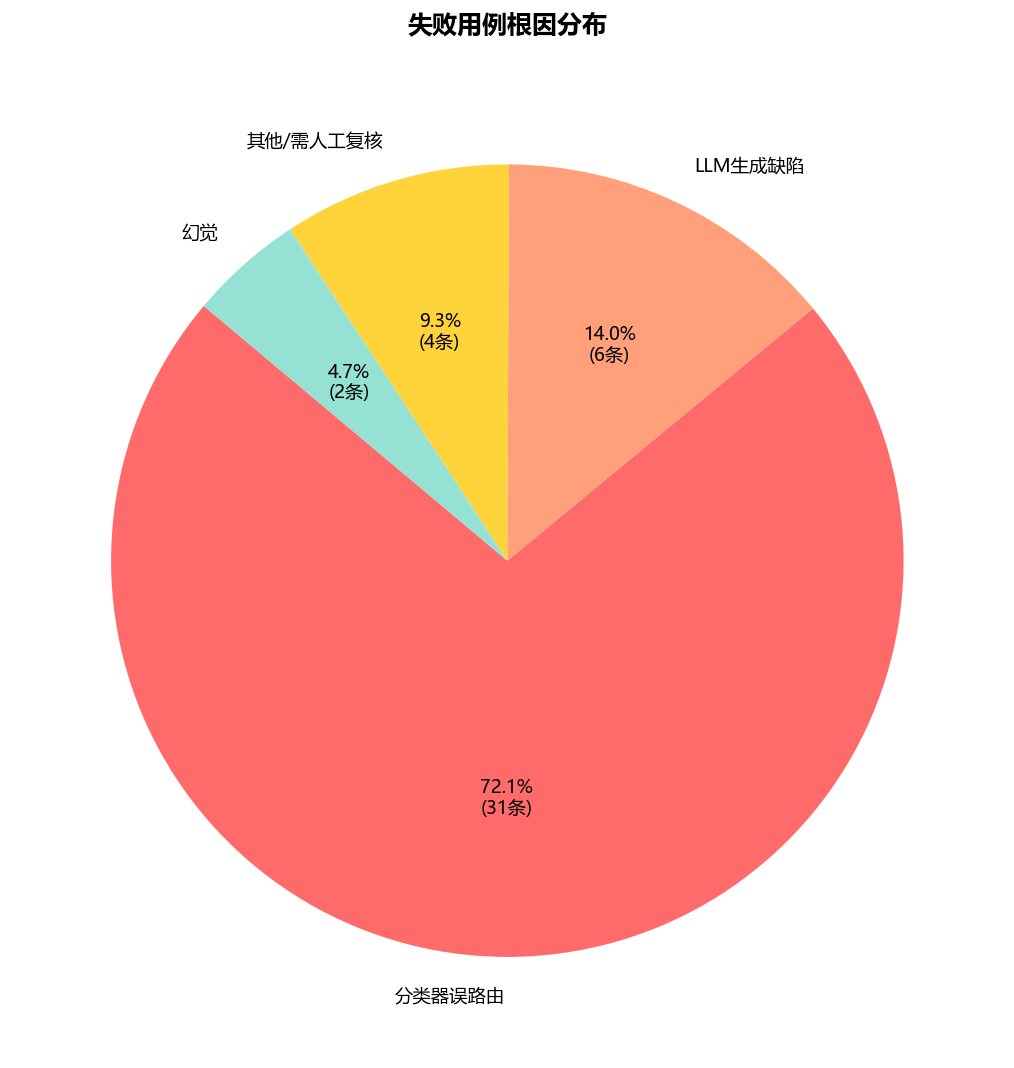

💾 已保存: charts/07_root_cause_pie.png


In [6]:
# ========== 图1：根因分布饼图 ==========
fig, ax = plt.subplots(figsize=(9, 9))

rc_counts = df_failed['root_cause_name'].value_counts()
colors = ['#FF6B6B', '#FFA07A', '#FFD43B', '#95E1D3',
          '#4ECDC4', '#45B7D1', '#C44569', '#D3D4DA']

wedges, texts, autotexts = ax.pie(
    rc_counts.values,
    labels    = rc_counts.index,
    autopct   = lambda p: f'{p:.1f}%\n({int(p*len(df_failed)/100)}条)',
    colors    = colors[:len(rc_counts)],
    startangle = 140,
    textprops = {'fontsize': 11},
)

ax.set_title('失败用例根因分布', fontsize=15, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('charts/07_root_cause_pie.png')
plt.show()
print('💾 已保存: charts/07_root_cause_pie.png')



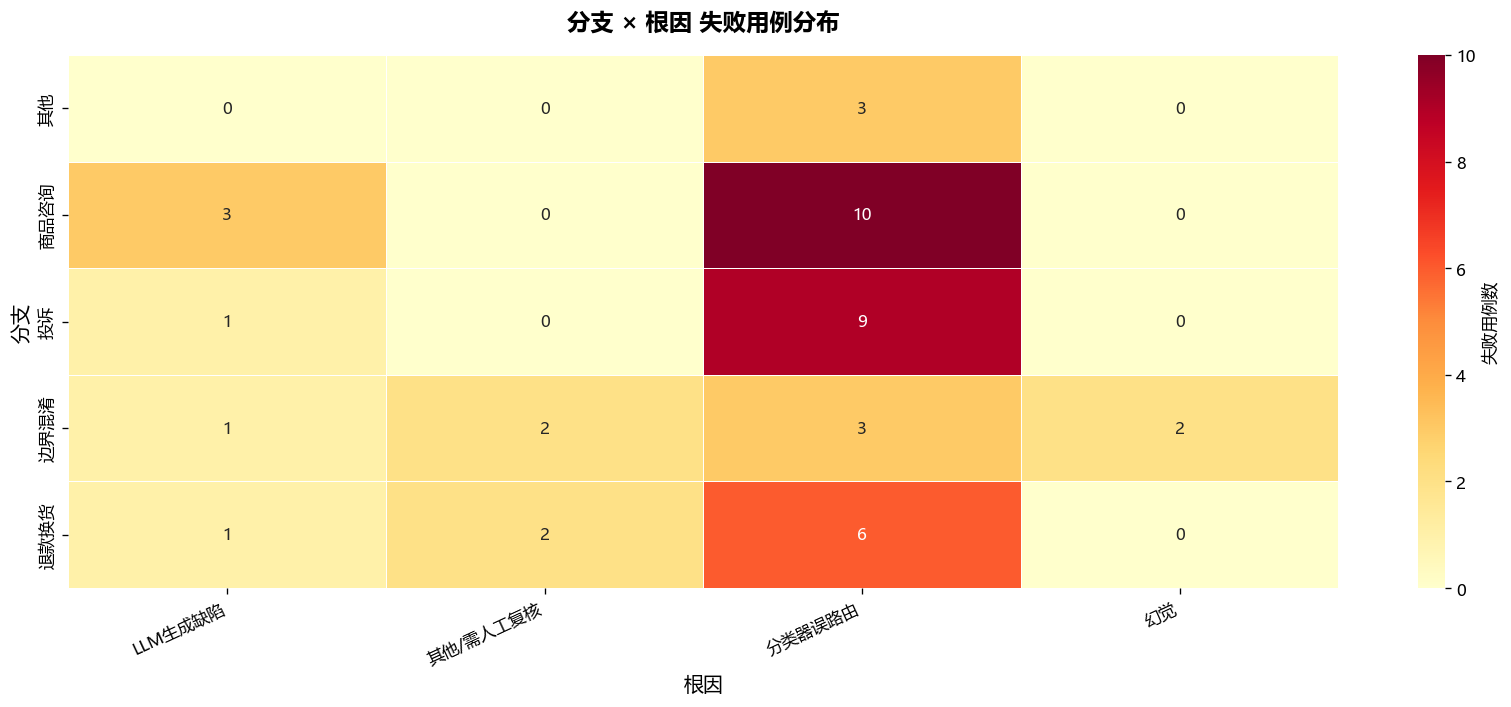

💾 已保存: charts/08_branch_rootcause_heatmap.png


In [7]:
# ========== 图2：分支 × 根因 热力图 ==========
import seaborn as sns

fig, ax = plt.subplots(figsize=(14, 6))

cross_no_margin = pd.crosstab(
    df_failed['category'],
    df_failed['root_cause_name'],
)

sns.heatmap(
    cross_no_margin,
    annot      = True,
    fmt        = 'd',
    cmap       = 'YlOrRd',
    ax         = ax,
    linewidths = 0.5,
    cbar_kws   = {'label': '失败用例数'},
)

ax.set_title('分支 × 根因 失败用例分布', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('根因', fontsize=12)
ax.set_ylabel('分支', fontsize=12)
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.savefig('charts/08_branch_rootcause_heatmap.png')
plt.show()
print('💾 已保存: charts/08_branch_rootcause_heatmap.png')



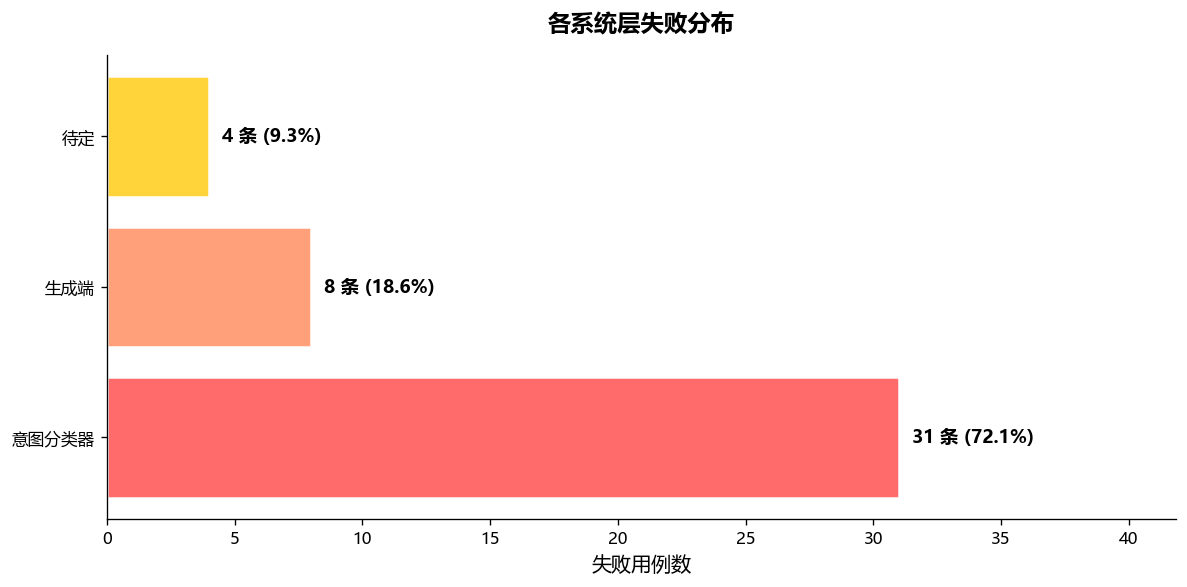

💾 已保存: charts/09_system_layer_failures.png


In [8]:
# ========== 图3：系统层失败分布柱状图 ==========
fig, ax = plt.subplots(figsize=(10, 5))

layer_counts = df_failed['system_layer'].value_counts()
bar_colors = ['#FF6B6B', '#FFA07A', '#FFD43B', '#4ECDC4',
              '#45B7D1', '#C44569', '#95E1D3']

bars = ax.barh(
    layer_counts.index,
    layer_counts.values,
    color     = bar_colors[:len(layer_counts)],
    edgecolor = 'white',
    linewidth = 1.5,
)

for bar, cnt in zip(bars, layer_counts.values):
    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f'{cnt} 条 ({cnt/len(df_failed)*100:.1f}%)',
        ha='left', va='center', fontsize=11, fontweight='bold',
    )

ax.set_xlabel('失败用例数', fontsize=12)
ax.set_title('各系统层失败分布', fontsize=14, fontweight='bold', pad=15)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_xlim(0, max(layer_counts.values) * 1.35)

plt.tight_layout()
plt.savefig('charts/09_system_layer_failures.png')
plt.show()
print('💾 已保存: charts/09_system_layer_failures.png')



## 2.8 典型失败模式提取


In [9]:
# ========== 提取典型失败模式 ==========
print('=' * 60)
print('📋 典型失败模式')
print('=' * 60)

patterns = []

# 模式1: 分类器误路由
r1_cases = df_failed[df_failed['root_cause_code'] == 'R1']
if len(r1_cases) > 0:
    print(f"\n--- 模式1: 分类器误路由 ({len(r1_cases)} 条) ---")
    for _, r in r1_cases.head(5).iterrows():
        print(f"  [{r['case_id']}] Q: {str(r['user_query'])[:50]}...")
        print(f"    期望分支: {r['expected_branch']} | 路由分: {r['branch_routing']} | 意图分: {r['intent_accuracy']}")
        print(f"    评论: {str(r.get('comment', ''))[:80]}")
    patterns.append(('分类器误路由', len(r1_cases), '分类器对边界 case 路由不稳定，需硬化决策树'))

# 模式2: 幻觉
r4_cases = df_failed[df_failed['root_cause_code'] == 'R4']
if len(r4_cases) > 0:
    print(f"\n--- 模式2: 幻觉 ({len(r4_cases)} 条) ---")
    for _, r in r4_cases.head(3).iterrows():
        print(f"  [{r['case_id']}] Q: {str(r['user_query'])[:50]}...")
        print(f"    回复片段: {str(r.get('actual_response', ''))[:80]}...")
    patterns.append(('幻觉', len(r4_cases), 'LLM 在知识库未命中时虚构信息，需加防护指令'))

# 模式3: 知识检索失败
r2_cases = df_failed[df_failed['root_cause_code'] == 'R2']
if len(r2_cases) > 0:
    print(f"\n--- 模式3: 知识检索失败 ({len(r2_cases)} 条) ---")
    for _, r in r2_cases.head(3).iterrows():
        print(f"  [{r['case_id']}] Q: {str(r['user_query'])[:50]}...")
        print(f"    期望要点: {str(r.get('expected_answer_contains', ''))[:60]}")
        print(f"    要点覆盖: {r.get('contains_expected_points', 'N/A')}")
    patterns.append(('知识检索失败', len(r2_cases), 'KB 语义匹配不足，需调阈值或优化分块策略'))

# 模式4: 禁止表述违规
r5_cases = df_failed[df_failed['root_cause_code'] == 'R5']
if len(r5_cases) > 0:
    print(f"\n--- 模式4: 禁止表述违规 ({len(r5_cases)} 条) ---")
    for _, r in r5_cases.head(3).iterrows():
        print(f"  [{r['case_id']}] Q: {str(r['user_query'])[:50]}...")
        print(f"    must_not: {str(r.get('must_not', ''))[:60]}")
    patterns.append(('禁止表述违规', len(r5_cases), 'LLM 提示词未内置禁止表述清单'))

# 模式5: 边界判定错误
r6_cases = df_failed[df_failed['root_cause_code'] == 'R6']
if len(r6_cases) > 0:
    print(f"\n--- 模式5: 边界判定错误 ({len(r6_cases)} 条) ---")
    for _, r in r6_cases.head(3).iterrows():
        print(f"  [{r['case_id']}] Q: {str(r['user_query'])[:50]}...")
        print(f"    边界值: {r.get('boundary_value', 'N/A')} | 边界分: {r.get('boundary_correctness', 'N/A')}")
    patterns.append(('边界判定错误', len(r6_cases), 'IF/ELSE 条件未正确处理边界值'))

# 模式6: LLM 生成缺陷
r3_cases = df_failed[df_failed['root_cause_code'] == 'R3']
if len(r3_cases) > 0:
    print(f"\n--- 模式6: LLM 生成缺陷 ({len(r3_cases)} 条) ---")
    for _, r in r3_cases.head(3).iterrows():
        print(f"  [{r['case_id']}] Q: {str(r['user_query'])[:50]}...")
        print(f"    完整性: {r.get('information_completeness', 'N/A')} | 相关性: {r.get('answer_relevance', 'N/A')}")
    patterns.append(('LLM生成缺陷', len(r3_cases), '生成端输出不完整或偏离问题'))

# 模式7: 多轮上下文丢失
r7_cases = df_failed[df_failed['root_cause_code'] == 'R7']
if len(r7_cases) > 0:
    print(f"\n--- 模式7: 多轮上下文丢失 ({len(r7_cases)} 条) ---")
    for _, r in r7_cases.head(3).iterrows():
        print(f"  [{r['case_id']}] Q: {str(r['user_query'])[:50]}...")
        print(f"    多轮: {r.get('is_multi_turn', 'N/A')} | 意图分: {r.get('intent_accuracy', 'N/A')}")
    patterns.append(('多轮上下文丢失', len(r7_cases), '会话管理未正确维护上下文状态'))

# 模式汇总
print(f"\n--- 模式汇总 ---")
for name, cnt, suggestion in patterns:
    print(f"  {name:14s}: {cnt:3d} 条 → {suggestion}")



📋 典型失败模式

--- 模式1: 分类器误路由 (31 条) ---
  [TC-IF6-IF] Q: 快递延迟了两天还没到，我很着急...
    期望分支: 投诉 | 路由分: 2 | 意图分: 3
    评论: [预检修正]must_not未违规(精确匹配)。未体现投诉分支核心动作（致歉、补偿），仅机械索要订单号，缺失期望要点‘抱歉’和‘补偿’。
  [TC-BOUND-010] Q: 4999元的商品需要本人签收吗...
    期望分支: 商品咨询 | 路由分: 1 | 意图分: 2
    评论: [预检修正]must_not未违规(精确匹配)。未响应边界值（4999<5000），未给出‘不需要本人签收’等关键要点，错误推诿至知识库缺失。
  [TC-MULTI-002] Q: 续航多久...
    期望分支: 商品咨询 | 路由分: 1 | 意图分: 2
    评论: [预检修正]must_not未违规(精确匹配)。未回应已明确的商品（WF-1000XM5）和问题（续航），且未提供已知关键信息‘30小时’，属严重信息缺失。
  [TC-PROHIB-001] Q: 退款多久到账...
    期望分支: 商品咨询 | 路由分: 1 | 意图分: 5
    评论: [预检修正]must_not未违规(精确匹配)。路由错误：用户问退款到账时效，属'退款咨询'分支，非'商品咨询'分支。
  [TC-PROHIB-005] Q: 什么时候发货...
    期望分支: 商品咨询 | 路由分: 1 | 意图分: 2
    评论: [预检修正]must_not未违规(精确匹配)。未提及'16:00/当日/次日'任一要点；虚构'节假日发货安排''双十一时效延长'等无依据信息；路由错误，应答商

--- 模式2: 幻觉 (2 条) ---
  [TC-BND-005] Q: 快递太慢了我要投诉还要退款...
    回复片段: 非常抱歉给您带来了不愉快的体验，感谢您的反馈。我们已收到您的投诉，并会尽快处理。根据您的描述，我们将为您安排退换货，24小时内完成。请您放心，我们会加快速度解决...
  [TC-BND-018] Q: 你们的客服不专业要投诉要退款...
    回复片段: 非常抱歉给您带来了不愉快的体验，我们深感歉意。请您放心，我们会立即为您处

## 2.9 关键发现总结


In [10]:
# ========== 关键发现总结 ==========
print('=' * 60)
print('📋 模块二：失败归因分析 — 关键发现')
print('=' * 60)

total_failed = len(df_failed)
total_all    = 505

# 根因排名
rc_rank     = df_failed['root_cause_name'].value_counts()
top_rc_name = rc_rank.index[0]
top_rc_cnt  = rc_rank.iloc[0]
top_rc_pct  = top_rc_cnt / total_failed * 100

# 系统层排名
layer_rank    = df_failed['system_layer'].value_counts()
top_layer     = layer_rank.index[0]
top_layer_cnt = layer_rank.iloc[0]

# 最严重分支
branch_fail   = df_failed['category'].value_counts()
top_fail_br   = branch_fail.index[0]
top_fail_cnt  = branch_fail.iloc[0]

# 交叉分析：哪个分支×根因组合最多
cross_pairs   = df_failed.groupby(['category', 'root_cause_name']).size().sort_values(ascending=False)
top_pair      = cross_pairs.index[0]
top_pair_cnt  = cross_pairs.iloc[0]

print(f"""
┌──────────────────────────────────────────────────┐
│ 1. 失败规模                                     │
├──────────────────────────────────────────────────┤
│   失败用例:    {total_failed} / {total_all} = {total_failed/total_all*100:.1f}%           │
│   涉及分支:    {df_failed['category'].nunique()} 个                       │
│   涉及根因:    {df_failed['root_cause_name'].nunique()} 种                       │
├──────────────────────────────────────────────────┤
│ 2. 头号根因                                   │
├──────────────────────────────────────────────────┤
│   {top_rc_name:14s} ({top_rc_cnt} 条, {top_rc_pct:.1f}%)           │
│   → 该根因是系统最大短板，优化优先级最高    │
├──────────────────────────────────────────────────┤
│ 3. 失败最多的系统层                         │
├──────────────────────────────────────────────────┤
│   {top_layer:14s} ({top_layer_cnt} 条)               │
│   → {top_layer} 是优化的核心战场               │
├──────────────────────────────────────────────────┤
│ 4. 失败最多的分支                             │
├──────────────────────────────────────────────────┤
│   {top_fail_br:14s} ({top_fail_cnt} 条)               │
│   → 需优先针对该分支进行优化                │
├──────────────────────────────────────────────────┤
│ 5. 最集中的分支×根因组合                      │
├──────────────────────────────────────────────────┤
│   {top_pair[0]:10s} × {top_pair[1]:12s} ({top_pair_cnt} 条)    │
│   → 该组合是最高优先级的修复目标            │
└──────────────────────────────────────────────────┘

6. 根因分布
--------------------------------------------------""")

for name, cnt in rc_rank.items():
    pct = cnt / total_failed * 100
    bar = '█' * int(pct / 2)
    print(f"   {name:14s} {cnt:3d} ({pct:5.1f}%) {bar}")

print(f"""
7. 优化建议（按优先级排序）
--------------------------------------------------""")

suggestions = sorted(patterns, key=lambda x: x[1], reverse=True)
for i, (name, cnt, suggestion) in enumerate(suggestions, 1):
    print(f"   P{i} {name:12s} ({cnt:3d}条): {suggestion}")

print(f"""
→ 下一步: 进入模块三（相关性分析），
  探究各评分维度间的内在关联，识别杠杆维度
""")



📋 模块二：失败归因分析 — 关键发现

┌──────────────────────────────────────────────────┐
│ 1. 失败规模                                     │
├──────────────────────────────────────────────────┤
│   失败用例:    43 / 505 = 8.5%           │
│   涉及分支:    5 个                       │
│   涉及根因:    4 种                       │
├──────────────────────────────────────────────────┤
│ 2. 头号根因                                   │
├──────────────────────────────────────────────────┤
│   分类器误路由         (31 条, 72.1%)           │
│   → 该根因是系统最大短板，优化优先级最高    │
├──────────────────────────────────────────────────┤
│ 3. 失败最多的系统层                         │
├──────────────────────────────────────────────────┤
│   意图分类器          (31 条)               │
│   → 意图分类器 是优化的核心战场               │
├──────────────────────────────────────────────────┤
│ 4. 失败最多的分支                             │
├──────────────────────────────────────────────────┤
│   商品咨询           (13 条)               │
│   → 需优先针对该分支进行优化                │
├──────────────────────

## 2.10 导出分析结果


In [11]:
# ========== 导出带根因标签的失败用例 ==========
df_failed.to_csv(
    'analysis_output/module2_failure_attribution.csv',
    index=False, encoding='utf-8-sig',
)

# 导出根因统计
rc_summary = df_failed.groupby(
    ['root_cause_code', 'root_cause_name', 'system_layer']
).agg(
    count = ('case_id', 'count'),
    pct   = ('case_id', lambda x: len(x) / len(df_failed) * 100),
).reset_index().sort_values('count', ascending=False)

rc_summary.to_csv(
    'analysis_output/module2_root_cause_summary.csv',
    index=False, encoding='utf-8-sig',
)

# 导出分支×根因交叉表
cross_export = pd.crosstab(
    df_failed['category'],
    df_failed['root_cause_name'],
    margins=True,
)
cross_export.to_csv(
    'analysis_output/module2_branch_rootcause_cross.csv',
    encoding='utf-8-sig',
)

print('✅ 模块二导出完成')
print(f'   📄 module2_failure_attribution.csv  ({len(df_failed)} 条 → 模块三输入)')
print(f'   📄 module2_root_cause_summary.csv  (根因统计汇总)')
print(f'   📄 module2_branch_rootcause_cross.csv (分支×根因交叉表)')
print(f'   📊 charts/07_root_cause_pie.png')
print(f'   📊 charts/08_branch_rootcause_heatmap.png')
print(f'   📊 charts/09_system_layer_failures.png')



✅ 模块二导出完成
   📄 module2_failure_attribution.csv  (43 条 → 模块三输入)
   📄 module2_root_cause_summary.csv  (根因统计汇总)
   📄 module2_branch_rootcause_cross.csv (分支×根因交叉表)
   📊 charts/07_root_cause_pie.png
   📊 charts/08_branch_rootcause_heatmap.png
   📊 charts/09_system_layer_failures.png
